# 02 · Models: predicting remaining useful life (RUL)

**Goal:** predict how many cycles each engine has left (NASA C-MAPSS, FD001).
**Plan:** baseline → linear models → Random Forest → XGBoost / LightGBM, all compared with the same 5-fold cross-validation split by engine. Every run is logged in MLflow. The official test set is used **once**, at the end.

In [8]:
%pip install mlflow

  Obtaining dependency information for mlflow from https://files.pythonhosted.org/packages/78/a6/d693e1b3d704d6728a9746cd065bbb58fe19c8558d62536e2d5accd00709/mlflow-3.17.2-py3-none-any.whl.metadata
  Using cached mlflow-3.17.2-py3-none-any.whl.metadata (50 kB)
  Obtaining dependency information for mlflow-skinny==3.17.2 from https://files.pythonhosted.org/packages/e9/57/f1071a3f1aa2898d4fec13c359405c996a8f1c6786ebfff062144504076a/mlflow_skinny-3.17.2-py3-none-any.whl.metadata
  Using cached mlflow_skinny-3.17.2-py3-none-any.whl.metadata (51 kB)
  Obtaining dependency information for mlflow-tracing==3.17.2 from https://files.pythonhosted.org/packages/db/6b/ebac062a2c6619c16feaafba349b07c1f03ce6b0b0f6d3af79d936a17380/mlflow_tracing-3.17.2-py3-none-any.whl.metadata
  Using cached mlflow_tracing-3.17.2-py3-none-any.whl.metadata (19 kB)
  Obtaining dependency information for Flask-CORS<7 from https://files.pythonhosted.org/packages/49/55/5bb1a2d918e9f02f131e47a59032bae70e48050e986e941511fd7


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install xgboost lightgbm catboost

  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/2f/3c/925394671f6a1668e2a71886de66e80be694eaf37f615cec74eefaf43107/xgboost-3.4.1-py3-none-win_amd64.whl.metadata
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Obtaining dependency information for lightgbm from https://files.pythonhosted.org/packages/d5/0b/c5c17d862b12ce292f24cd85d40f2f8f8981668fbdbd43fdc2625eccbc79/lightgbm-4.7.0-py3-none-win_amd64.whl.metadata
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Obtaining dependency information for catboost from https://files.pythonhosted.org/packages/93/e2/f467a133b37eef2b3d8697d46a6e7f0da24bd3643f5475817c473ffc41dc/catboost-1.2.10-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for graphviz from https://files.pythonhosted.org/packages/91/4c/e0ce1ef95d4000ebc1c11801f9b944fa5910ecc15b5e351865763d8657f8/graphviz-0.21-py3-none-any.whl.metadata
  Obtaining dependency information fo


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")           

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from src.features import load_cmapss, add_rul, make_features, feature_columns, SENSORS
from src.evaluate import rmse, nasa_score, evaluate_cv

RUL_CAP = 125
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("engine-rul")

2026/11/02 21:07:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 21:07:25 INFO mlflow.store.db.utils: Updating database tables
2026/11/02 21:07:49 INFO mlflow.tracking.fluent: Experiment with name 'engine-rul' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:///e:/Github Projects/Project/1#1/NASA C-MAPSS turbofan degradation '
 'dataset/CMaps/Engine-Failure-Prediction/notebooks/mlruns'), creation_time=1793642869575, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793642869575, lifecycle_stage='active', name='engine-rul', tags={}, trace_location=None, workspace='default'>

## 2. Load data and create the target

In [2]:
train = load_cmapss("../data/train_FD001.txt")
test = load_cmapss("../data/test_FD001.txt")
true_rul = pd.read_csv("../data/RUL_FD001.txt", header=None, names=["RUL"])
train = add_rul(train, cap=RUL_CAP)
print("train:", train.shape, "| test:", test.shape, "| test engines:", len(true_rul))
print("sensors used:", len(SENSORS), SENSORS)
train[["unit", "cycle", "RUL"]].head()

train: (20631, 27) | test: (13096, 26) | test engines: 100
sensors used: 14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


,unit,cycle,RUL
0,1,1,125
1,1,2,125
2,1,3,125
3,1,4,125
4,1,5,125


## 3. Helper: run one experiment and log it to MLflow

In [3]:
results = []   # collects one row per experiment for the final table

def run_experiment(name, model, X, y, groups, extra_params=None):
    print(name)
    with mlflow.start_run(run_name=name):
        cv_rmse, oof = evaluate_cv(model, X, y, groups)
        mlflow.log_params({"model": type(model).__name__,
                           "rul_cap": RUL_CAP,
                           "n_features": X.shape[1],
                           **(extra_params or {})})
        mlflow.log_metric("cv_rmse", cv_rmse)
    results.append({"experiment": name, "n_features": X.shape[1], "cv_rmse": round(cv_rmse, 2)})
    return oof

## 4. Baseline and models on raw sensors
Inputs: the 14 informative sensors + `cycle`. `groups` tells cross-validation which engine each row belongs to, so one engine is never in both train and validation.

In [4]:
raw_cols = SENSORS + ["cycle"]
X_raw = train[raw_cols]
y = train["RUL"]
groups = train["unit"]

run_experiment("baseline_mean", DummyRegressor(strategy="mean"), X_raw, y, groups)
run_experiment("linear_raw", LinearRegression(), X_raw, y, groups)

baseline_mean
  fold 1: RMSE = 41.68
  fold 2: RMSE = 41.67
  fold 3: RMSE = 41.67
  fold 4: RMSE = 41.67
  fold 5: RMSE = 41.67
  mean RMSE = 41.67 ± 0.00
linear_raw
  fold 1: RMSE = 21.92
  fold 2: RMSE = 20.44
  fold 3: RMSE = 20.42
  fold 4: RMSE = 17.65
  fold 5: RMSE = 20.17
  mean RMSE = 20.12 ± 1.38


array([132.5614229 , 129.84477067, 134.84478823, ...,   6.00306022,
         2.65364135,   4.65216781], shape=(20631,))

## 5. Add rolling features

In [6]:
train_feat = make_features(train)
feat_cols = feature_columns(train_feat)
X = train_feat[feat_cols]
y = train_feat["RUL"]
groups = train_feat["unit"]
print(len(feat_cols), "features")

113 features


## 6. Models with rolling features

In [7]:
run_experiment("linear_rolling",
               make_pipeline(StandardScaler(), LinearRegression()), X, y, groups)

rf_params = {"n_estimators": 200, "max_depth": 12, "min_samples_leaf": 5}
run_experiment("random_forest",
               RandomForestRegressor(**rf_params, n_jobs=-1, random_state=42),
               X, y, groups, rf_params)

linear_rolling
  fold 1: RMSE = 17.09
  fold 2: RMSE = 16.28
  fold 3: RMSE = 16.34
  fold 4: RMSE = 15.31
  fold 5: RMSE = 17.06
  mean RMSE = 16.42 ± 0.65
random_forest
  fold 1: RMSE = 16.04
  fold 2: RMSE = 15.83
  fold 3: RMSE = 14.49
  fold 4: RMSE = 15.16
  fold 5: RMSE = 15.50
  mean RMSE = 15.41 ± 0.55


array([124.99339146, 124.99339024, 123.85194153, ...,   1.44387165,
         1.25354695,   0.80578584], shape=(20631,))

In [8]:
xgb_params = {"n_estimators": 500, "max_depth": 5, "learning_rate": 0.05,
              "subsample": 0.8, "colsample_bytree": 0.8}
oof_xgb = run_experiment("xgboost",
                         XGBRegressor(**xgb_params, n_jobs=-1, random_state=42),
                         X, y, groups, xgb_params)

lgb_params = {"n_estimators": 500, "num_leaves": 31, "learning_rate": 0.05,
              "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8}
oof_lgb = run_experiment("lightgbm",
                         LGBMRegressor(**lgb_params, random_state=42, verbose=-1),
                         X, y, groups, lgb_params)

xgboost
  fold 1: RMSE = 14.28
  fold 2: RMSE = 14.55
  fold 3: RMSE = 13.79
  fold 4: RMSE = 13.29
  fold 5: RMSE = 14.92
  mean RMSE = 14.17 ± 0.57
lightgbm
  fold 1: RMSE = 14.31
  fold 2: RMSE = 14.59
  fold 3: RMSE = 13.79
  fold 4: RMSE = 13.62
  fold 5: RMSE = 15.02
  mean RMSE = 14.27 ± 0.51


## 7. Small tuning of XGBoost
Change one thing at a time. Every try is logged in MLflow.

In [9]:
for depth in [3, 4, 6]:
    for lr in [0.03, 0.1]:
        p = xgb_params | {"max_depth": depth, "learning_rate": lr}
        run_experiment(f"xgb_d{depth}_lr{lr}",
                       XGBRegressor(**p, random_state=42, n_jobs=-1), X, y, groups, p)

xgb_d3_lr0.03
  fold 1: RMSE = 15.41
  fold 2: RMSE = 14.35
  fold 3: RMSE = 14.32
  fold 4: RMSE = 13.86
  fold 5: RMSE = 15.36
  mean RMSE = 14.66 ± 0.62
xgb_d3_lr0.1
  fold 1: RMSE = 14.84
  fold 2: RMSE = 14.28
  fold 3: RMSE = 14.02
  fold 4: RMSE = 13.04
  fold 5: RMSE = 14.92
  mean RMSE = 14.22 ± 0.68
xgb_d4_lr0.03
  fold 1: RMSE = 14.87
  fold 2: RMSE = 14.45
  fold 3: RMSE = 14.08
  fold 4: RMSE = 13.56
  fold 5: RMSE = 14.93
  mean RMSE = 14.38 ± 0.51
xgb_d4_lr0.1
  fold 1: RMSE = 14.59
  fold 2: RMSE = 14.20
  fold 3: RMSE = 14.00
  fold 4: RMSE = 13.17
  fold 5: RMSE = 15.02
  mean RMSE = 14.20 ± 0.62
xgb_d6_lr0.03
  fold 1: RMSE = 14.46
  fold 2: RMSE = 14.62
  fold 3: RMSE = 13.65
  fold 4: RMSE = 13.44
  fold 5: RMSE = 14.93
  mean RMSE = 14.22 ± 0.58
xgb_d6_lr0.1
  fold 1: RMSE = 14.49
  fold 2: RMSE = 15.00
  fold 3: RMSE = 13.67
  fold 4: RMSE = 13.73
  fold 5: RMSE = 15.20
  mean RMSE = 14.42 ± 0.63


## 8. Cross-validation results

In [10]:
cv_table = pd.DataFrame(results).sort_values("cv_rmse").reset_index(drop=True)
cv_table

,experiment,n_features,cv_rmse
0,xgboost,113,14.17
1,xgb_d4_lr0.1,113,14.20
2,xgb_d6_lr0.03,113,14.22
3,xgb_d3_lr0.1,113,14.22
4,lightgbm,113,14.27
5,xgb_d4_lr0.03,113,14.38
6,xgb_d6_lr0.1,113,14.42
7,xgb_d3_lr0.03,113,14.66
8,random_forest,113,15.41
9,linear_rolling,113,16.42


### Cross-validation results

**Best model: XGBoost (default settings: depth 5, learning rate 0.05), CV RMSE = 14.17 cycles.**

- **vs baseline** (always predict the mean, 41.67): error is **66% lower** (27.5 cycles less). The model has clearly learned the degradation pattern.
- **vs linear regression on raw sensors** (20.12): **30% lower**.
- **vs linear regression with rolling features** (16.42): **14% lower**. Non-linear models capture the curved degradation trend better.

**What helped most:**
1. **Rolling features:** they cut linear regression error from 20.12 to 16.42 (18% better). Trends over the last 5 to 30 cycles carry more information than one noisy reading.
2. **Tree boosting:** XGBoost and LightGBM (14.17 vs 14.27) beat Random Forest (15.41).

**Tuning made almost no difference:** all XGBoost versions fall between 14.17 and 14.66. The model is not sensitive to these settings, so I keep the default version. Further gains will come from features or the RUL cap, not from tuning.

## 9. Error analysis
Using out-of-fold predictions: every engine is predicted by a model that never saw it.

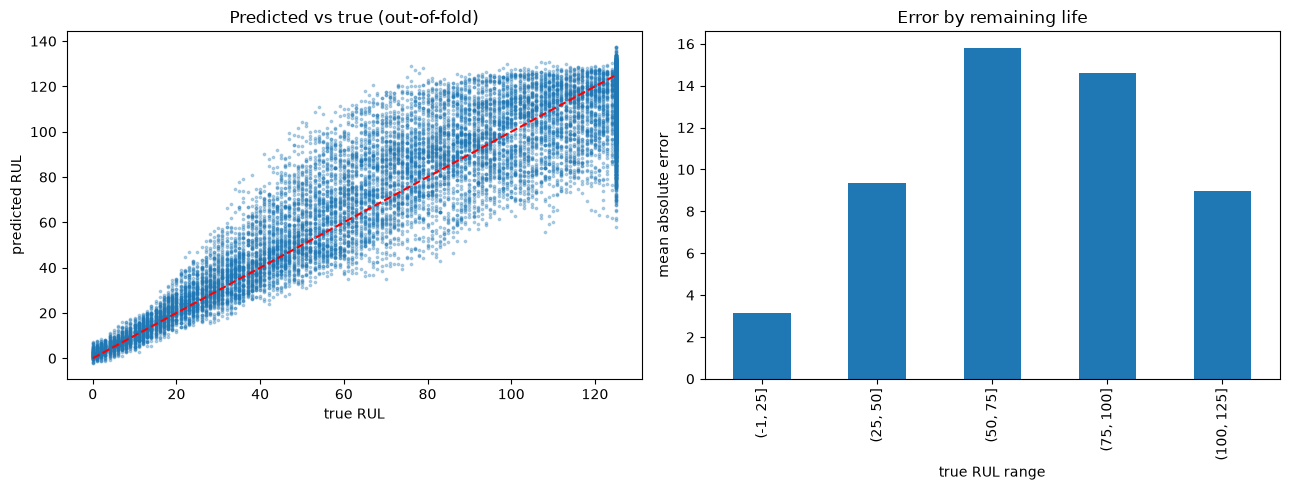

Late predictions (predicted > true + 10 cycles): 16.2% of rows


In [11]:
best_oof = oof_xgb          
err = best_oof - y.values 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y, best_oof, s=3, alpha=0.3)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--")
axes[0].set(xlabel="true RUL", ylabel="predicted RUL", title="Predicted vs true (out-of-fold)")

bins = pd.cut(y, bins=[-1, 25, 50, 75, 100, RUL_CAP])
pd.Series(np.abs(err)).groupby(bins.values).mean().plot.bar(ax=axes[1])
axes[1].set(xlabel="true RUL range", ylabel="mean absolute error", title="Error by remaining life")
plt.tight_layout()
plt.savefig("../images/pred_vs_true.png", dpi=120)
plt.show()

print(f"Late predictions (predicted > true + 10 cycles): {(err > 10).mean():.1%} of rows")

In [12]:
near = y.values <= 30
print(f"Late predictions near failure (true RUL <= 30): {(err[near] > 10).mean():.1%}")

Late predictions near failure (true RUL <= 30): 6.2%


**Error analysis:** prediction error shrinks as failure approaches: about 3 cycles mean absolute error when fewer than 25 cycles remain, versus about 15 cycles in the 50 to 100 range, where degradation has only just started and the sensor signal is weak. 16.2% of predictions are more than 10 cycles late (overestimate life), mostly in the mid-life range; near failure (RUL ≤ 30) the late rate is 6.2%. Possible improvements: an asymmetric loss that penalises late predictions, or longer rolling windows to detect the start of degradation earlier.

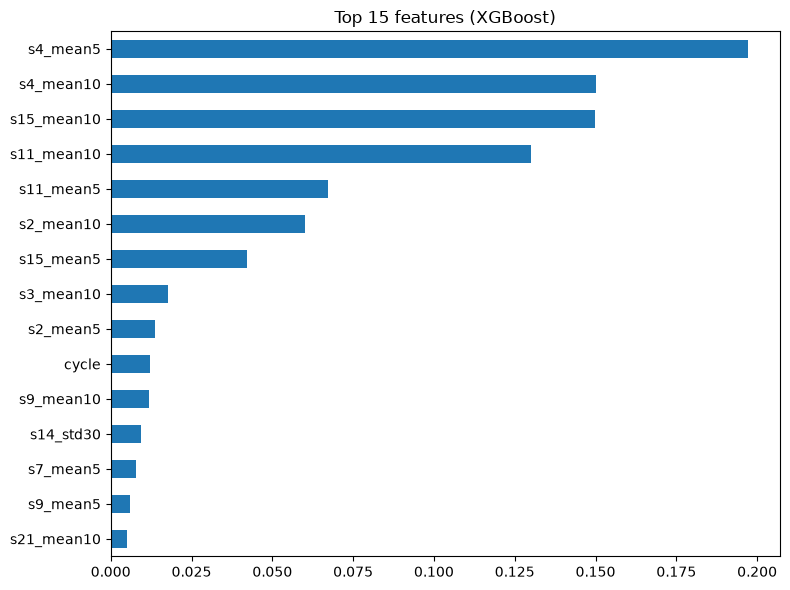

In [13]:
best_model = XGBRegressor(**xgb_params, random_state=42, n_jobs=-1).fit(X, y)
imp = pd.Series(best_model.feature_importances_, index=feat_cols).sort_values(ascending=False)
imp.head(15).plot.barh(figsize=(8, 6)).invert_yaxis()
plt.title("Top 15 features (XGBoost)")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=120)
plt.show()

## 10. Final test
Each test engine stops before failure, and `RUL_FD001.txt` gives its true RUL at the **last** recorded cycle. So: build features on the full test history, keep the last row per engine, compare with the true RUL.

In [15]:
test_feat = make_features(test)
test_last = test_feat.groupby("unit").tail(1).sort_values("unit").reset_index(drop=True)
X_test = test_last[feat_cols]
y_test = true_rul["RUL"].clip(upper=RUL_CAP).values

final_models = {
    "baseline_mean": DummyRegressor(strategy="mean"),
    "linear_rolling": make_pipeline(StandardScaler(), LinearRegression()),
    "random_forest": RandomForestRegressor(**rf_params, n_jobs=-1, random_state=42),
    "xgboost": XGBRegressor(**xgb_params, random_state=42, n_jobs=-1),
    "lightgbm": LGBMRegressor(**lgb_params, random_state=42, verbose=-1),
}

test_rows = []
for name, model in final_models.items():
    model.fit(X, y)
    pred = np.clip(model.predict(X_test), 0, None)
    test_rows.append({"model": name,
                      "test_rmse": round(rmse(y_test, pred), 2),
                      "nasa_score": round(nasa_score(y_test, pred), 1)})

with mlflow.start_run(run_name="final_test_xgboost"):
    mlflow.log_params(xgb_params | {"rul_cap": RUL_CAP})
    row = next(r for r in test_rows if r["model"] == "xgboost")
    mlflow.log_metrics({"test_rmse": row["test_rmse"], "nasa_score": row["nasa_score"]})
    mlflow.xgboost.log_model(final_models["xgboost"], name="model")

test_table = pd.DataFrame(test_rows).sort_values("test_rmse").reset_index(drop=True)
test_table.to_csv("../images/test_results.csv", index=False)
test_table

,model,test_rmse,nasa_score
0,lightgbm,14.31,329.1
1,xgboost,14.88,367.9
2,linear_rolling,15.84,375.5
3,random_forest,15.94,431.2
4,baseline_mean,41.94,33354.5


### The selected model "XGBOOST" predicts remaining engine life within about 15 cycles on unseen engines, 65% better than the baseline. Test RMSE (14.88) is close to cross-validation RMSE (14.17), so the model generalises well. LightGBM and XGBoost perform similarly; the difference is within the variation expected from 100 test engines. Rolling-window features gave the biggest single gain: even a linear model reaches 15.84 with them.